# 02 · Análisis exploratorio

Objetivo: entender cómo evoluciona el delito en el tiempo y en el territorio antes de modelarlo. Todo el análisis usa **tasas por 100.000 habitantes**, para que los cantones sean comparables.

Periodo: 2015–2025 (años completos). 2026 se reserva para la prueba final del modelo.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import oij, viz

viz.estilo()
FIG = RAIZ / 'reports' / 'figures'
EXT = RAIZ / 'data' / 'external'
DELITOS = oij.DELITOS
ET = viz.ETIQUETAS_DELITO

## 1. Datos

Registros del OIJ, población cantonal, Índice de Desarrollo Social y límites cantonales.

In [2]:
df = oij.cargar_todos(RAIZ / 'data' / 'raw')
df = df[~df['Canton'].isin(oij.VALORES_DESCONOCIDOS) & df['Fecha'].notna()]
hist = df[df['Anio'] <= 2025]

pob = pd.read_csv(EXT / 'poblacion_cantonal.csv')
ids = pd.read_csv(EXT / 'ids_2023_cantonal.csv').set_index('Canton')
geo = viz.cargar_geometrias(EXT / 'cantones.geojson')

print(f'{len(hist):,} delitos de 2015 a 2025 en {hist.Canton.nunique()} cantones')

549,304 delitos de 2015 a 2025 en 81 cantones


Tabla de tasas por cantón, año y tipo de delito (se guarda para los siguientes notebooks).

In [3]:
anual = (hist.groupby(['Canton', 'Anio', 'Delito']).size().unstack(fill_value=0)
        .reindex(columns=DELITOS, fill_value=0).stack().rename('Delitos').reset_index())
anual = anual.merge(pob[['Canton', 'Anio', 'Poblacion']], on=['Canton', 'Anio'])
anual['Tasa'] = anual['Delitos'] / anual['Poblacion'] * 1e5
anual.to_parquet(RAIZ / 'data' / 'processed' / 'tasas_canton_anio.parquet', index=False)
anual.head()

,Canton,Anio,Delito,Delitos,Poblacion,Tasa
0,ABANGARES,2015,HURTO,53,19600,270.408163
1,ABANGARES,2015,ASALTO,14,19600,71.428571
2,ABANGARES,2015,ROBO,63,19600,321.428571
3,ABANGARES,2015,ROBO DE VEHICULO,11,19600,56.122449
4,ABANGARES,2015,TACHA DE VEHICULO,9,19600,45.918367


## 2. La paradoja: menos delitos, pero más violentos

Tasa nacional por tipo de delito, con 2015 como base 100.

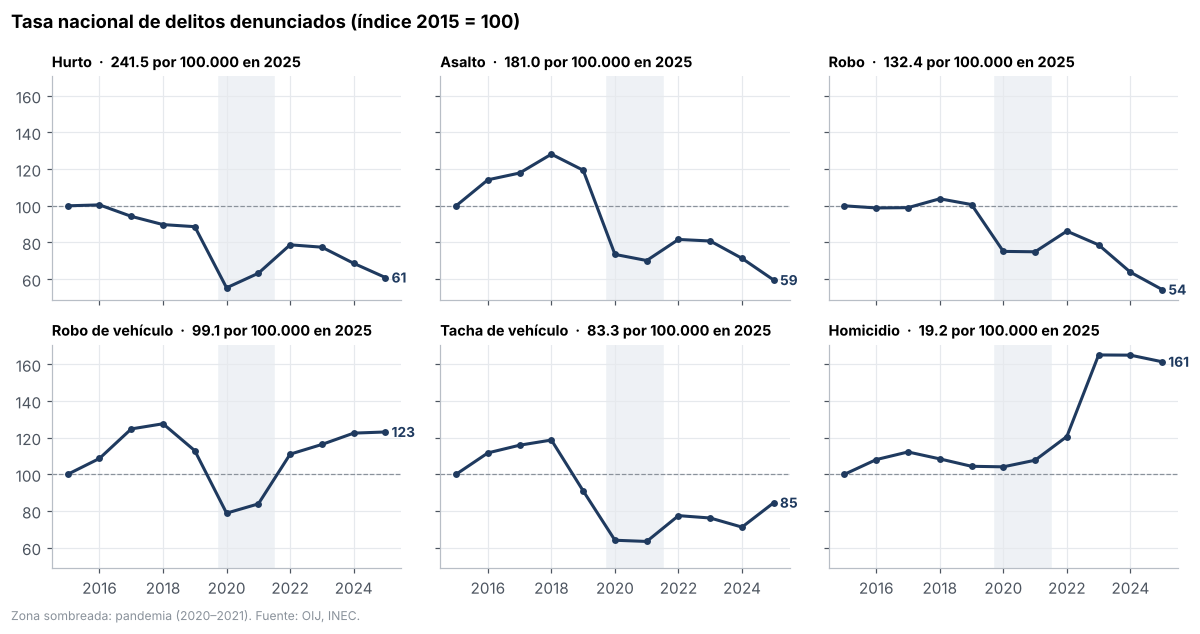

In [4]:
nac = hist.groupby(['Anio', 'Delito']).size().unstack()[DELITOS]
pob_nac = pob.groupby('Anio')['Poblacion'].sum()
tasa_nac = nac.div(pob_nac.loc[nac.index], axis=0) * 1e5
indice = tasa_nac / tasa_nac.loc[2015] * 100

fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True, sharey=True)
for ax, d in zip(axes.flat, DELITOS):
    ax.axhline(100, color=viz.GRIS, lw=0.8, ls='--')
    ax.axvspan(2019.75, 2021.5, color='#eef1f5', zorder=0)
    ax.plot(indice.index, indice[d], color=viz.AZUL, lw=2, marker='o', ms=3.5)
    fin = indice[d].iloc[-1]
    ax.annotate(f'{fin:.0f}', (indice.index[-1], fin), xytext=(4, 0), textcoords='offset points',
                va='center', fontsize=9, fontweight='bold', color=viz.AZUL)
    ax.set_title(f"{ET[d]}  ·  {tasa_nac[d].iloc[-1]:.1f} por 100.000 en 2025", fontsize=9.5)
fig.suptitle('Tasa nacional de delitos denunciados (índice 2015 = 100)', x=0.01, ha='left', fontweight='bold')
fig.text(0.01, -0.01, 'Zona sombreada: pandemia (2020–2021). Fuente: OIJ, INEC.', fontsize=8, color=viz.GRIS)
fig.tight_layout()
fig.savefig(FIG / '02_paradoja_indice_nacional.png')

In [5]:
tasa_nac.round(1)

Delito,HURTO,ASALTO,ROBO,ROBO DE VEHICULO,TACHA DE VEHICULO,HOMICIDIO
Anio,,,,,,
2015,396.6,304.3,243.6,80.5,98.5,11.9
2016,398.6,347.4,240.8,87.5,110.0,12.8
2017,373.8,358.7,241.2,100.5,114.2,13.3
2018,356.0,390.0,253.0,102.7,116.9,12.9
2019,351.5,363.3,245.3,90.9,89.6,12.4
2020,219.2,223.7,183.1,63.5,63.1,12.4
2021,250.8,213.5,182.6,67.5,62.4,12.8
2022,312.2,248.5,210.0,89.4,76.3,14.3
2023,307.1,245.9,191.7,93.6,75.0,19.6


**Lectura:**

- **Los delitos contra la propiedad bajaron mucho:** en 2025 el asalto, el hurto y el robo están entre un 40 % y un 46 % por debajo de 2015 en tasa por habitante.
- **La violencia letal subió:** la tasa de homicidios pasó de 11,9 a 19,2 por 100.000 (+61 %), con el salto en 2023. El robo de vehículos también está un 23 % por encima de 2015.
- **La pandemia rompe la serie:** en 2020 caen todos los delitos contra la propiedad y no recuperan el nivel previo. El modelo debe tratar 2020–2021 como un periodo excepcional.
- Parte de la caída puede ser **menos denuncia** y no menos delito; los datos no permiten separarlo.

**Implicación para el modelo:** cada tipo de delito sigue su propia tendencia, así que se modelará por separado (o con el tipo como variable).

## 3. Estacionalidad

Índice mensual y semanal: 1,00 es el promedio; 1,10 significa un 10 % más de lo normal. Se excluyen 2020 y 2021 para que la pandemia no distorsione el patrón.

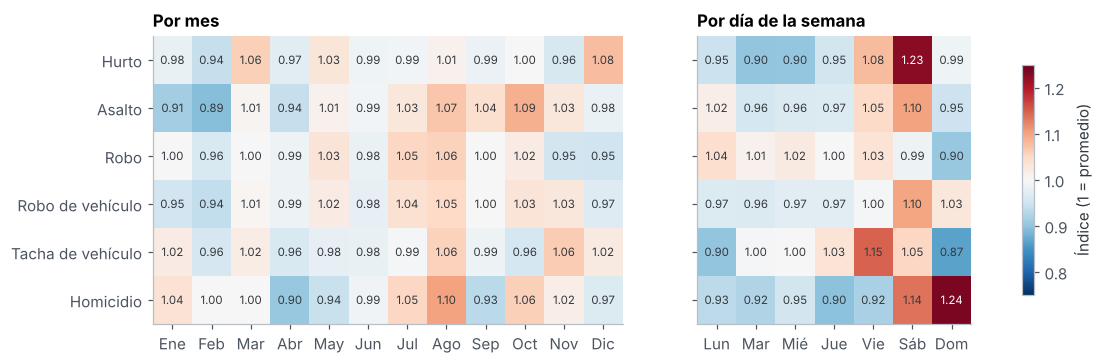

In [6]:
normal = hist[~hist['Anio'].isin([2020, 2021])]
mes = normal.groupby([normal['Fecha'].dt.month, 'Delito']).size().unstack()[DELITOS]
mes = (mes / mes.mean()).T
dia = normal.groupby([normal['Fecha'].dt.dayofweek, 'Delito']).size().unstack()[DELITOS]
dia = (dia / dia.mean()).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [12, 7]})
for ax, tabla, cols, titulo in [(axes[0], mes, ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic'], 'Por mes'),
                                (axes[1], dia, ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'], 'Por día de la semana')]:
    im = ax.imshow(tabla.values, cmap='RdBu_r', vmin=0.75, vmax=1.25, aspect='auto')
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(DELITOS)), [ET[d] for d in DELITOS])
    ax.grid(False); ax.set_title(titulo)
    for (i, j), v in np.ndenumerate(tabla.values):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(v - 1) > 0.15 else '#33393f')
axes[1].set_yticklabels([])
fig.colorbar(im, ax=axes, shrink=0.8, label='Índice (1 = promedio)')
fig.savefig(FIG / '02_estacionalidad.png')

**Lectura:**

- **La estacionalidad mensual es moderada** (±10 %): el asalto sube en el segundo semestre (agosto–octubre) y baja en febrero; el hurto sube en diciembre y marzo.
- **El día de la semana pesa más:** el hurto sube un 23 % los sábados, la tacha de vehículos un 15 % los viernes y el homicidio se concentra en el fin de semana (+24 % los domingos).
- **Implicación:** el modelo mensual debe incluir el mes y el número de fines de semana de cada mes, que varía entre 8 y 10.

## 4. Geografía del delito

Tasa media anual 2023–2025 por cantón. Las clases son quintiles de cada mapa, así que cada uno muestra el ranking relativo de los cantones para ese delito.

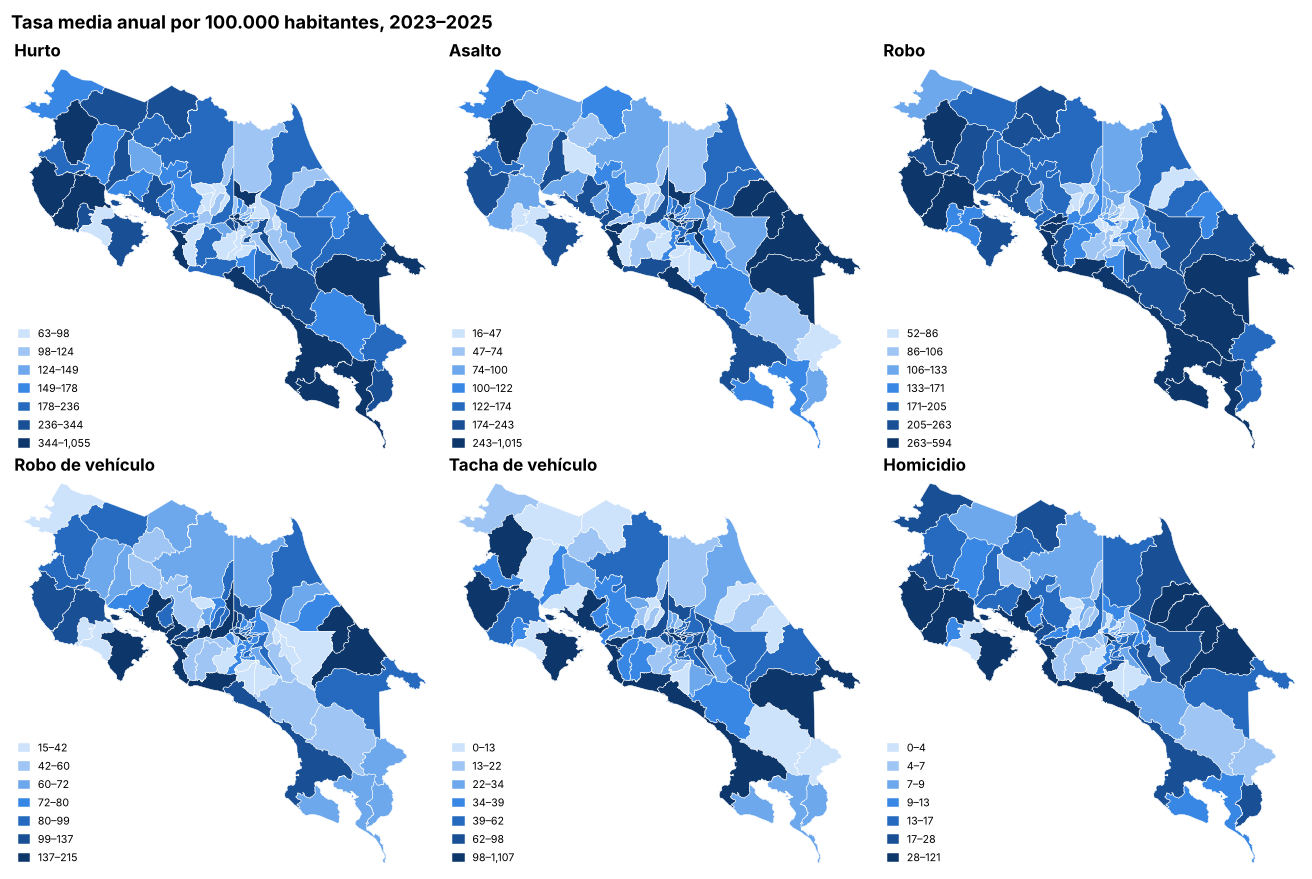

In [7]:
rec = anual[anual['Anio'].between(2023, 2025)].groupby(['Canton', 'Delito'])[['Delitos', 'Poblacion']].sum()
tasa_rec = (rec['Delitos'] / rec['Poblacion'] * 1e5).unstack()[DELITOS]
tot = rec.groupby('Canton').agg(Delitos=('Delitos', 'sum'), Poblacion=('Poblacion', 'first'))
tasa_rec['TOTAL'] = tot['Delitos'] / tot['Poblacion'] * 1e5  # Poblacion ya es la suma de los 3 años

fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
for ax, d in zip(axes.flat, DELITOS):
    viz.mapa(ax, geo, tasa_rec[d], titulo=ET[d], formato='{:,.0f}')
fig.suptitle('Tasa media anual por 100.000 habitantes, 2023–2025', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIG / '02_mapas_tasa_por_delito.png')

### Ranking por tasa frente a ranking por volumen

In [8]:
conteo = rec['Delitos'].groupby('Canton').sum()
comp = pd.DataFrame({
    'Top 10 por tasa': tasa_rec['TOTAL'].sort_values(ascending=False).head(10).index.str.title(),
    'Tasa total': tasa_rec['TOTAL'].sort_values(ascending=False).head(10).round(0).values,
    'Top 10 por volumen': conteo.sort_values(ascending=False).head(10).index.str.title(),
    'Delitos 2023–2025': conteo.sort_values(ascending=False).head(10).values,
}, index=range(1, 11))
comp

,Top 10 por tasa,Tasa total,Top 10 por volumen,Delitos 2023–2025
1,Garabito,2919.0,San Jose,27449
2,San Jose,2647.0,Alajuela,8420
3,Osa,1966.0,Heredia,4757
4,Quepos,1757.0,Puntarenas,4537
5,Montes De Oca,1400.0,Cartago,4217
6,Talamanca,1375.0,San Carlos,3833
7,Liberia,1360.0,Desamparados,3315
8,Santa Cruz,1340.0,Liberia,3309
9,Orotina,1288.0,Perez Zeledon,3047
10,Parrita,1211.0,Limon,3036


In [9]:
orden = conteo.sort_values(ascending=False)
pob_rec = pob[pob['Anio'] == 2025].set_index('Canton')['Poblacion']
print(f"Los 10 cantones con más delitos concentran el {orden.head(10).sum()/orden.sum():.0%} de los casos "
      f"y el {pob_rec[orden.head(10).index].sum()/pob_rec.sum():.0%} de la población.")

Los 10 cantones con más delitos concentran el 51% de los casos y el 37% de la población.


**Lectura:**

- **Por volumen domina el Valle Central** (San José, Alajuela, Heredia, Cartago). Los 10 cantones con más delitos concentran la mitad de los casos con algo más de un tercio de la población.
- **Por tasa dominan los cantones turísticos de costa:** Garabito, Osa, Quepos, Santa Cruz, Talamanca y Liberia. Su tasa se calcula sobre los residentes, pero reciben una gran población flotante de turistas, así que la tasa por residente sobrestima el riesgo por persona presente. Aun así, para asignar recursos lo relevante es el volumen de delitos que ocurren allí.
- **El homicidio tiene su propia geografía:** se concentra en el Caribe (Limón, Matina) y el Pacífico Central (Parrita, Quepos, Garabito, Puntarenas).
- **Implicación:** el modelo debe incluir alguna medida de **turismo** o población flotante, y la priorización final debe combinar tasa y volumen.

## 5. Relación con el desarrollo social

Correlación de Spearman (por rangos) entre la tasa 2023–2025 de cada delito y las dimensiones del IDS 2023. La dimensión de seguridad del IDS se excluye porque se calcula con datos de criminalidad.

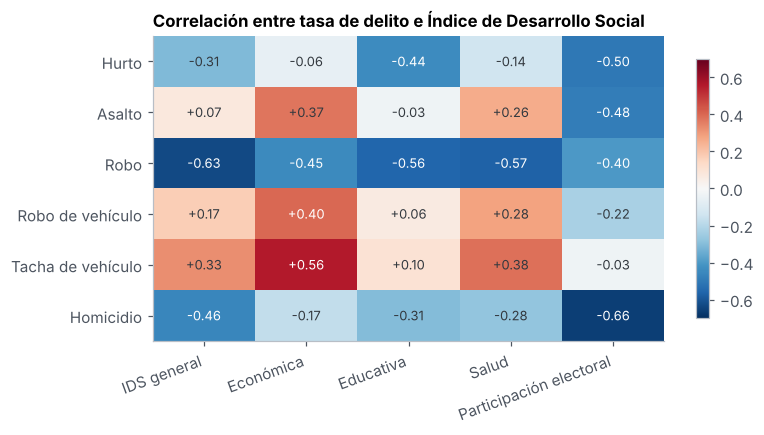

In [10]:
dims = {'IDS': 'IDS general', 'IDS_economica': 'Económica', 'IDS_educativa': 'Educativa',
        'IDS_salud': 'Salud', 'IDS_participacion': 'Participación electoral'}
cor = tasa_rec.join(ids[list(dims)]).corr(method='spearman').loc[DELITOS, list(dims)]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(cor.values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
ax.set_xticks(range(len(dims)), dims.values(), rotation=20, ha='right')
ax.set_yticks(range(len(DELITOS)), [ET[d] for d in DELITOS]); ax.grid(False)
for (i, j), v in np.ndenumerate(cor.values):
    ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=8.5, color='white' if abs(v) > 0.4 else '#33393f')
ax.set_title('Correlación entre tasa de delito e Índice de Desarrollo Social')
fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig(FIG / '02_correlacion_ids.png')

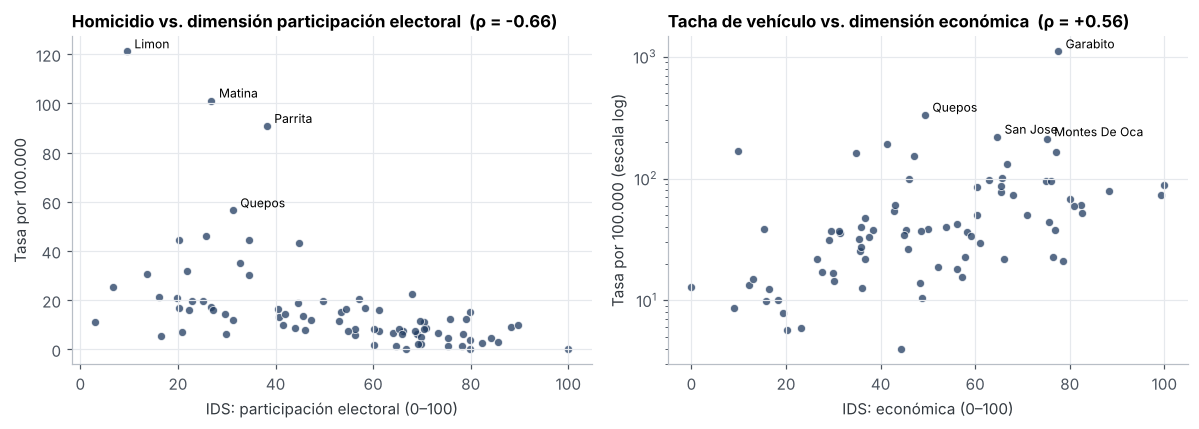

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, dim in [(axes[0], 'HOMICIDIO', 'IDS_participacion'), (axes[1], 'TACHA DE VEHICULO', 'IDS_economica')]:
    x, y = ids[dim], tasa_rec[d].reindex(ids.index)
    ax.scatter(x, y, s=28, color=viz.AZUL, alpha=0.75, edgecolor='white', lw=0.6)
    for c in y.sort_values(ascending=False).head(4).index:
        ax.annotate(c.title(), (x[c], y[c]), xytext=(5, 2), textcoords='offset points', fontsize=8)
    ax.set_xlabel(f'IDS: {dims[dim].lower()} (0–100)'); ax.set_ylabel('Tasa por 100.000')
    ax.set_title(f"{ET[d]} vs. dimensión {dims[dim].lower()}  (ρ = {cor.loc[d, dim]:+.2f})")
axes[1].set_yscale('log'); axes[1].set_ylabel('Tasa por 100.000 (escala log)')
fig.tight_layout()
fig.savefig(FIG / '02_dispersion_ids.png')

**Lectura:** el desarrollo social se relaciona con el delito de dos formas opuestas.

- **Delitos asociados a la vulnerabilidad:** el homicidio y el robo son más frecuentes donde el desarrollo es menor. La relación más fuerte es con la participación electoral (ρ = −0,66 para homicidio), que suele interpretarse como un indicador de cohesión social.
- **Delitos de oportunidad:** la tacha y el robo de vehículos son más frecuentes donde la dimensión económica es **mayor** (ρ = +0,56 para tacha), porque hay más vehículos y más bienes que sustraer.
- **Implicación:** las dimensiones del IDS son buenas variables explicativas, pero su efecto cambia de signo según el delito. Es otro argumento para modelar por tipo de delito o permitir interacciones, algo que los modelos de árboles capturan bien.
- El IDS es una foto de 2023: sirve para explicar diferencias **entre** cantones, no cambios en el tiempo.

## 6. Eventos masivos y picos puntuales

Días en que un cantón registró muchas veces más delitos que su promedio diario (mínimo 25 delitos ese día). Se excluyen 2020 y 2021.

In [12]:
diario = normal.groupby(['Canton', normal['Fecha'].dt.normalize()]).size().rename('Delitos')
media = normal.groupby('Canton').size() / normal['Fecha'].dt.normalize().nunique()
picos = diario.reset_index()
picos['Veces el promedio'] = picos['Delitos'] / picos['Canton'].map(media)
picos = picos[picos['Delitos'] >= 25].sort_values('Veces el promedio', ascending=False).head(15)
picos['Hurtos'] = [((normal['Canton'] == c) & (normal['Fecha'] == f) & (normal['Delito'] == 'HURTO')).sum()
                   for c, f in zip(picos['Canton'], picos['Fecha'])]
picos.assign(Canton=picos['Canton'].str.title(), Fecha=picos['Fecha'].dt.strftime('%d/%m/%Y'),
             **{'Veces el promedio': picos['Veces el promedio'].round(0)}).reset_index(drop=True)

,Canton,Fecha,Delitos,Veces el promedio,Hurtos
0,Santa Cruz,17/01/2015,203,73.0,187
1,Belen,10/02/2024,53,63.0,43
2,Belen,23/04/2022,49,59.0,49
3,Palmares,15/01/2015,28,55.0,25
4,Belen,04/02/2023,37,44.0,31
5,Belen,08/02/2025,27,32.0,23
6,Belen,26/10/2019,25,30.0,22
7,San Carlos,08/07/2015,87,19.0,4
8,Escazu,23/03/2018,28,18.0,0
9,Tibas,05/11/2022,34,17.0,25


**Lectura:** la mayoría de los picos extremos son **hurtos concentrados en un solo día**, y se repiten en fechas y lugares asociados a eventos masivos:

- **Santa Cruz y Palmares en enero**, coincidiendo con sus fiestas cívicas tradicionales; ambos cantones tienen enero como su mes con más delitos (el doble de su promedio mensual).
- **Belén y Tibás**, que albergan recintos de conciertos y el Estadio Saprissa, con picos aislados en fines de semana.
- **Liberia a finales de julio**, en torno a las celebraciones del 25 de julio.

Algunos picos no son hurtos (San Carlos en julio de 2015, Escazú en marzo de 2018): probablemente son denuncias registradas en bloque, y el modelo debe ser robusto a ellos. Las fechas concretas de cada evento quedan por verificar, pero el patrón es claro. **Implicación:** un **calendario de eventos masivos** (fiestas cantonales, conciertos y partidos) es una variable con potencial predictivo alto para el hurto. Las fiestas tienen fecha fija y se pueden anticipar, lo que encaja con un sistema de alerta temprana.

## 7. Conclusiones para la modelización

1. **Modelar por tipo de delito:** las tendencias van en direcciones opuestas (propiedad a la baja, homicidio y robo de vehículos al alza).
2. **Tratar la pandemia como ruptura:** una variable indicadora para 2020–2021 y validación centrada en el periodo posterior.
3. **Variables de calendario:** mes, número de fines de semana del mes y un calendario de fiestas y eventos masivos por cantón.
4. **Variables estructurales del cantón:** IDS (sin la dimensión de seguridad), población y una medida de turismo.
5. **Dependencia espacial:** los mapas sugieren que los cantones vecinos se parecen (Caribe, Pacífico Central); se comprobará formalmente en el notebook 03.
6. **Priorización:** combinar tasa (riesgo por habitante) y volumen (carga de trabajo) al definir el ranking final.